In [1]:
import os, sys

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    sys.path.append(module_path)
sys.path.append(os.getcwd())

import numpy as np
import scipy
%matplotlib notebook

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection, LineCollection, Collection
from matplotlib.path import Path
from mpl_toolkits.mplot3d import Axes3D

from scipy.stats import pearsonr, spearmanr
import math
import torch
import gpytorch
from matplotlib import pyplot as plt
import plotly.graph_objects as go

import seaborn as sns
from scipy.spatial import ConvexHull, convex_hull_plot_2d

import pandas as pd
import pickle as pkl

import trimesh
import gymnasium as gym

from argparse import Namespace

from lap.sac_airl_lap_liver import Actor, SoftQNetwork
from lap.ppo_airl_lap_liver import Agent

#from lap.sac_gail_lap_liver import Actor
from irl.airl import AIRLDiscriminator
from irl.gail import GAILDiscriminator
from envs.env_lap_liver import plt_sphere
from irl.utils import load_lap_demos

import ot

from texttable import Texttable
import latextable

from tqdm.notebook import tqdm

#%matplotlib inline
%load_ext autoreload
%autoreload 2

/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/flatbuffers/compat.py:19: DeprecationWarning: the imp module is deprecated in favour of importlib; see the module's documentation for alternative uses
  import imp
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/keras/protobuf/versions_pb2.py:18: DeprecationWarning: Call to deprecated create function FileDescriptor(). Note: Create unlinked descriptors is going to go away. Please use get/find descriptors from generated code or query the descriptor_pool.
  DESCRIPTOR = _descriptor.FileDescriptor(
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/keras/protobuf/versions_pb2.py:36: DeprecationWarning: Call to deprecated create function FieldDescriptor(). Note: Create unlinked descriptors is going to go away. Please use get/find descriptors from generated code or query the descriptor_pool.
  _descriptor.FieldDescriptor(
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/keras/protobuf/versions

In [3]:
data_dict = {}
for f in os.listdir('.'):
    if 'npy' in f:
        data_dict[f] = np.load(f)
   
df1 = pd.read_excel('DiagnosticLaparoscopy_UnknownPathology_2021-18-10--14-48-56.xls')
df2 = pd.read_excel('DiagnosticLaparoscopy_UnknownPathology_2021-18-10--14-48-57.xls')

df1_filtered = df1[df1['Total score']>100]
df2_filtered = df2[df2['Total score']>100]

df1.keys()

Index(['Section name', 'Scene name', 'User name:', 'User session', 'Report ID',
       'Report date', 'Exercise completed', 'Total score', 'Report items:',
       'Simulation overview', 'Simulation overview score',
       'Procedure time sec', 'Procedure time sec score', 'Economy',
       'Economy score', 'Camera path length cm', 'Camera path length cm score',
       'Total instruments path length cm',
       'Total instruments path length cm score',
       'Alignment of the scope horizon %',
       'Alignment of the scope horizon % score',
       'Idle time Atraumatic Grasping Forceps %',
       'Idle time Atraumatic Grasping Forceps % score',
       'Idle time Atraumatic Grasping Forceps sec',
       'Idle time Atraumatic Grasping Forceps sec score',
       'Atraumatic Grasping Forceps path length cm',
       'Atraumatic Grasping Forceps path length cm score',
       'Idle time Suction & Irrigation Device %',
       'Idle time Suction & Irrigation Device % score',
       'Idle time S

In [22]:
def as_mesh(scene_or_mesh):
    """
    Convert a possible scene to a mesh.

    If conversion occurs, the returned mesh has only vertex and face data.
    """
    if isinstance(scene_or_mesh, trimesh.Scene):
        if len(scene_or_mesh.geometry) == 0:
            mesh = None  # empty scene
        else:
            # we lose texture information here
            mesh = trimesh.util.concatenate(
                tuple(trimesh.Trimesh(vertices=g.vertices, faces=g.faces)
                      for g in scene_or_mesh.geometry.values()))
    else:
        assert(isinstance(scene_or_mesh, trimesh.Trimesh))
        mesh = scene_or_mesh
    return mesh

def load_mesh_tri(fname, simplify_mesh=False, scale=100):

    mesh = as_mesh(trimesh.load_mesh(fname))
    mesh.apply_scale(scale)
    if simplify_mesh and 'Belly' not in f:
        mesh = mesh.simplify_quadratic_decimation(2000)

    # apply gravity shift on everything but Belly
    if 'Belly' in fname:
        return mesh.vertices, mesh
    else:
        return mesh.vertices + np.tile((0,-2,0),(mesh.vertices.shape[0],1)), mesh

obj_dict = {}
for f in os.listdir('obj'):
    if '.obj' in f:
        #obj_dict[f] = load_obj(os.path.join('obj',f))
        obj_dict[f] = load_mesh_tri(os.path.join('obj',f))



In [5]:
### evaluate based on GAIL

In [6]:
def init_actor_disc(run_folder, demos, algo='ppo', disc='gail', best=False):
    args = pkl.load(open(os.path.join(run_folder,'hparams.pkl'),'rb'))

    args = Namespace(**args)
    print(os.listdir(run_folder))

    test_env = gym.make(args.env_id, gc=args.goal_conditioning, 
                             state_spec=args.state_spec, 
                             step_size=args.step_size,
                             done_on_collision=args.done_on_collision,
                             hard_collisions=args.hard_collisions,
                             plot_meshes=args.render_meshes,
                             continuous_actions=args.continuous_actions,
                             condition_on_n_tasks_completed=args.condition_on_n_tasks_completed,
                             collision_loss=args.collision_loss,
                             vis_threshold_factor = args.vis_threshold_factor,
                             mesh_folder='../davos_data/obj/',
                             ref_demo=demos)

    if args.normalize_obs and isinstance(test_env.action_space, gym.spaces.Box):
            env = gym.wrappers.NormalizeObservation(test_env)
            env = gym.wrappers.TransformObservation(env, lambda obs: np.clip(obs, -10, 10))
    if args.clip_action and isinstance(test_env.action_space, gym.spaces.Box):
        test_env = gym.wrappers.ClipAction(test_env)

    discrete = not isinstance(test_env.action_space, gym.spaces.Box)
    if disc == 'gail':
        disc = GAILDiscriminator(test_env, args)
    else:
        disc = AIRLDiscriminator(test_env, args)
      
    if best:
        disc.load_state_dict(torch.load(os.path.join(run_folder, "best_disc.pt")))
    else:
        disc.load_state_dict(torch.load(os.path.join(run_folder, "disc.pt")))

    #disc_airl = AIRLDiscriminator(test_env, args)
    #if args.load_disc:
    #    disc_airl.load_state_dict(torch.load(os.path.join(run_folder, "disc.pt") , map_location=device))

    if algo == 'ppo':
        actor = Agent(test_env)
        if best:
            actor.load_state_dict(torch.load(os.path.join(run_folder, "best_actor.pt")))
        else:
            actor.load_state_dict(torch.load(os.path.join(run_folder, "agent.pt")))
    else: # SAC
        actor = SoftQNetwork(test_env)
        if best:
            actor.load_state_dict(torch.load(os.path.join(run_folder, "best_qf1.pt")))
        else:
            actor.load_state_dict(torch.load(os.path.join(run_folder, "qf1.pt")))       

    return actor, disc, test_env

def evaluate_traj_disc_gail(test_env, disc, item):
    total_rew = 0
    pos_t = torch.from_numpy(item)
    with torch.no_grad():
        rew_ = disc.get_reward(pos_t, ac=None)
    return torch.sum(rew_)

def evaluate_traj_disc_airl(test_env, disc, item):
    total_rew = 0
    pos_t = torch.from_numpy(item)
    with torch.no_grad():
        rew_ = disc.reward(disc.base(pos_t))

    return torch.sum(rew_)

def evaluate_traj_value_ppo(test_env, agent, item):
    total_rew = 0
    pos_t = torch.from_numpy(item)
    with torch.no_grad():
        rew_ = agent.get_value(pos_t)
    return torch.sum(rew_)

def evaluate_traj_value_sac(test_env, qf, item):
    total_rew = 0
    pos_t = torch.from_numpy(item)
    ac0 = torch.zeros_like(torch.from_numpy(test_env.action_space.sample()))
    ac_t = torch.tile(ac0, (pos_t.shape[0],1))
    with torch.no_grad():
        rew_ = qf(pos_t,ac_t)
    return torch.sum(rew_)

def eval_data(test_env, actor, disc, data_dict, algo_type='ppo', disc_type='gail', score_type='Total score'):
    # evaluate data using trained models
    gt_score = []
    predicted_score_disc = []
    predicted_score_val = []

    for i, item in df1.iterrows():
        #df1['Attachments:']
        for item_k, item_v in data_dict.items():
            if item['Attachments:'][:8] == item_k[:8]:
                idx = ((item_v[:,-1] >= 12) & (item_v[:,-1] <= 14))
                gt_score.append(item[score_type])
                if disc_type == 'gail':
                    predicted_score_disc.append(evaluate_traj_disc_gail(test_env, disc, item_v[idx,:3]).numpy())
                else:
                    predicted_score_disc.append(evaluate_traj_disc_airl(test_env, disc, item_v[idx,:3]).numpy())

                if algo_type == 'ppo':
                    predicted_score_val.append(evaluate_traj_value_ppo(test_env, actor, item_v[idx,:3]).numpy())
                else:
                    predicted_score_val.append(evaluate_traj_value_sac(test_env, actor, item_v[idx,:3]).numpy())


                #print("GT trajectory score: ", item['Total score'], "Model score:", evaluate_traj(disc_gail, item_v[idx,:3]).numpy())

    #np.corrcoef(np.array(gt_score), np.stack(predicted_score))

    gt_score_normed = gt_score/np.linalg.norm(gt_score)
    predicted_score_disc_normed = predicted_score_disc/np.linalg.norm(predicted_score_disc)
    predicted_score_val_normed = predicted_score_val/np.linalg.norm(predicted_score_val)

    # calculate ranking
    gt_sorted_idx = np.argsort(gt_score_normed)
    predicted_sorted_idx = np.argsort(predicted_score_disc_normed)
    
    return gt_score_normed, predicted_score_disc_normed, predicted_score_val_normed

def eval_data_2(test_env, total_distance_score, total_safety_score, actor, disc, data_dict, algo_type='ppo', disc_type='gail', score_type='Total score'):
    # evaluate data using trained models
    dist_score = []
    safety_score = []
    predicted_score_disc = []
    predicted_score_val = []
    
    for item_k, item_v in data_dict.items():
        dist_score.append(total_distance_score[item_k])
        safety_score.append(total_safety_score[item_k])

        # TODO: hand select the indices
        idx = ((item_v[:,-1] >= 12) & (item_v[:,-1] <= 14))
        if disc_type == 'gail':
            predicted_score_disc.append(evaluate_traj_disc_gail(test_env, disc, item_v[idx,:3]).numpy())
        else:
            predicted_score_disc.append(evaluate_traj_disc_airl(test_env, disc, item_v[idx,:3]).numpy())

        if algo_type == 'ppo':
            predicted_score_val.append(evaluate_traj_value_ppo(test_env, actor, item_v[idx,:3]).numpy())
        else:
            predicted_score_val.append(evaluate_traj_value_sac(test_env, actor, item_v[idx,:3]).numpy())
            
            
    predicted_score_disc_normed = predicted_score_disc/np.linalg.norm(predicted_score_disc)
    predicted_score_val_normed = predicted_score_val/np.linalg.norm(predicted_score_val)

    return dist_score, safety_score, predicted_score_disc_normed, predicted_score_val_normed


def compute_instrument_distance(traj_, filter_idx):
    if filter_idx is not None:
        traj = []
        for idx in filter_idx:
            traj.extend(traj_[traj_[:,-1]==idx])
    
        traj = np.array(traj)
    else:
        traj = traj_


    if len(traj) > 0:
        total_covered_distance = 0
        for point, point_ in zip(traj[:-1], traj[1:]):
            total_covered_distance += np.linalg.norm(point_[:3] - point[:3])

        #total_covered_distance -= np.linalg.norm(traj[0,:3])
        return total_covered_distance
    
    else:
        return -1

from tqdm import tqdm

## calculate safety score by 
def min_vertex_distance(mesh, point):
    d = np.linalg.norm(mesh.vertices-point,-1)
    return np.min(d)

def total_min_vertex_distance(mesh, traj):
    total_distance = 0 
    for point in traj:
        total_distance += min_vertex_distance(mesh, point[:3])
        
    return total_distance

def compute_safety_scores(test_env, data_dict, filter_idx=[12,13,14]):
    safety_scores = {}
    for traj_k, traj_v in tqdm(data_dict.items()):
        safety_scores[traj_k] = {}
        if filter_idx is not None:
            traj = []
            for idx in filter_idx:
                traj.extend(traj_v[traj_v[:,-1]==idx])

            traj = np.array(traj)
        else:
            traj = traj_v
            
        for mesh_k,mesh_v in tqdm(test_env.meshes.items()):
            safety_scores[traj_k][mesh_k] = total_min_vertex_distance(mesh_v, traj_v)
            
    return safety_scores

def shortest_path_projection(centroids):
    dists = []
    for c,c_ in zip(centroids[:-1], centroids[1:]):
        d = c_-c 
        d = d/np.linalg.norm(d)
        
        dists.append(d)

    return dists


def compute_rollouts(test_env, actor, n_episodes=10):
    policy_traj = []
    with torch.no_grad():
        for i in range(n_episodes):
            traj = []
            o,_ = test_env.reset()
            o = o.reshape(1,-1)
            traj.append(o)
            done = False
            while not done:
                o_t = torch.from_numpy(o)
                a, lprobs, _, val = actor.get_action_and_value(o_t.reshape(1,-1))
                o,r,t,tr,i = test_env.step(a.detach().numpy())
                o = o.reshape(1,-1)
                traj.append(o)
                done = t or tr
                
            print(len(traj), traj[0].shape, traj[-1].shape)

            policy_traj.append(np.stack(traj))
                        
    return np.squeeze(np.concatenate(policy_traj,0))
            
def compute_sw2_distance(traj, demos):
    n = min(len(traj),len(demos))
    
    policy_atoms = np.array(traj[-n:])
    expert_atoms = np.array(demos[:n])
    
    sw2_dist = ot.sliced_wasserstein_distance(policy_atoms, expert_atoms, n_projections=500, seed=42)
    
    return sw2_dist

def compute_w2_distance(traj, demos):
    n = min(len(traj),len(demos))
    
    policy_atoms = np.array(traj[-n:])
    expert_atoms = np.array(demos[:n])
    
    
    M = ot.dist(policy_atoms, expert_atoms)
    a, b = np.ones((n,)) / n, np.ones((n,)) / n  # uniform distribution on samples
    #a, b = np.arange(n) / n, np.arange(n) / n  # uniform distribution on samples

    w2_dist = ot.emd2(a,b,M)
    
    return w2_dist

#points = np.random.randn(20,3)
#shortest_path_projection(points)
        

## (Deprecated) Load earlier version of data

### Plot bounding box rewards

### TODO:
- Find some evaluation ground truth metric which makes sense (ray projection + target ball occupancy / l2 norm to ray? Bc we eval on incomplete traj
- Try enhancing position features with distance to (all) anatomies -> safety features
- Try training on more targets?
- Compute W2 distance to target based on 10 rollouts! (load policy and sample using test_env)

### evaluate trajectory data and compute corr. coeffs against different ground truth scores given by simulator

### evaluate trajectory data and compute corr. coeffs against different ground truth scores computed separately

In [18]:
pkl.dump(total_safety_score, open('total_safety_score_new.pkl','wb'))
pkl.dump(total_distance_score, open('total_distance_score_new.pkl','wb'))
dist_sc = np.array(list(total_distance_score.values()))
safety_sc = np.array(list(total_safety_score.values()))
dist_sc_normed = dist_sc / np.linalg.norm(dist_sc)
safety_sc_normed = safety_sc / np.linalg.norm(safety_sc)

## Parse folder and do all the calculations

In [8]:
run_folder_ppo_gail___ = '../../runs/20240315_154558_997504_lap_ppo_gail_lap_liver__capture-video_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000_use_spectral_norm/'

# TODO: get run_folder with following variants over 10 seeds: (ppo / sac), (airl/gail), (sn, irm, lip, noreg) 
# Table: (algo variants) X (corr. coef variants) X (scores) + W2 / SW2 distance 
# Plot: 3d anatomy with trajectories / shading?, correlation plots x2, histogram of trajectory subset 

demos = load_lap_demos('.')

actor_sn, disc_sn, test_env = init_actor_disc(run_folder_ppo_gail___, demos)

Training on best trajectories: ['35da54b1-13ac-46.npy', '76c330f6-2f84-46.npy', 'aec679a0-c4ff-45.npy', '49ee32c0-1131-46.npy', '6d30c50e-1f3d-40.npy', 'f3c535fc-462c-45.npy', '108c5fb7-1a25-4e.npy', 'fb57fbba-d1a1-44.npy', 'b07a63c2-9a3f-41.npy', 'c41f4426-15b8-4f.npy', '39ec8da5-c73b-4c.npy', '875f87e6-f333-40.npy', 'bf2d94b0-752d-4b.npy', 'd58cd27d-096a-43.npy', '0e154d8e-85d8-4c.npy', '3b1148ed-a412-46.npy', '94162bd0-275e-48.npy', 'b9e91905-4f4c-4a.npy', '57dc9e10-26bb-46.npy', '0912d4e3-7e55-4e.npy', '9c74d9ee-ab25-46.npy', '60f1f42c-7040-4f.npy', 'e3634697-a87d-4e.npy', '95446495-71d0-4d.npy', '1552c740-2f6e-43.npy', '96a0b263-f925-46.npy', '0c598c36-d179-43.npy', 'bb0c2313-1b8a-4d.npy', '74e09eeb-6c21-4a.npy', 'c8acfd67-fc86-40.npy', '099b2d16-2281-4a.npy', 'bb5ea3fb-1487-4d.npy', '59813f92-c26a-42.npy', '9891a4c6-aec7-42.npy', '5d15c99e-aa26-41.npy', 'f92c6768-aa6d-45.npy', 'e92fae79-b782-45.npy', '2d3ae66d-e5e6-49.npy', 'f5275d64-8619-4a.npy', '423f3863-03e0-40.npy', 'f340543

In [12]:
d = {}
lins = ['--use_spectral_norm']
for irm_c in [0.0, 1.0, 10.0]:
    for lip_c in [0.0, 1.0, 10.0]:
        lins.append(f"--irm_coeff={irm_c} --lip_coeff={lip_c}")
        
def load_folder_results(test_env, demos, total_distance_score, total_safety_score, folder, d):
    hparams = pkl.load(open(os.path.join(folder, 'hparams.pkl'),'rb'))
    seed = hparams['seed']
    if 'gail' in folder:
        algo = 'gail'
    else:
        algo = 'airl'

    lin = ''
    irm_c = hparams['irm_coeff'] 
    lip_c = hparams['lip_coeff'] 

    if hparams['use_spectral_norm']:
        lin = '--use_spectral_norm'
    else:
        lin = f"--irm_coeff={irm_c} --lip_coeff={lip_c}"

    actor, disc, test_env = init_actor_disc(folder, demos, disc=algo)
    # evaluate rewards
    dist_score, safety_score, pr_sc_disc, pr_sc_val = eval_data_2(test_env, total_distance_score, total_safety_score, actor, disc, data_dict, disc_type=algo)
    dist_sc_normed = dist_score / np.linalg.norm(dist_score)
    safety_sc_normed = safety_score / np.linalg.norm(safety_score)

    # TODO evaluate rollouts and compute W2 distances
    policy_traj = np.array(compute_rollouts(test_env, actor))
    demos = load_lap_demos('.')['all']
    w2_dist = compute_w2_distance(policy_traj, demos['obs'])
    sw2_dist = compute_sw2_distance(policy_traj, demos['obs'])    
    # TODO: compute correlation coefficients

    ##pearson_cc_d = scipy.stats.pearsonr(dist_sc_normed, v)
    spearman_cc_d_rew = scipy.stats.spearmanr(dist_sc_normed, pr_sc_disc)
    spearman_cc_d_val = scipy.stats.spearmanr(dist_sc_normed, pr_sc_val)
    spearman_cc_s_rew = scipy.stats.spearmanr(safety_sc_normed, pr_sc_disc)
    spearman_cc_s_val = scipy.stats.spearmanr(safety_sc_normed, pr_sc_val)

    #kendall_cc_d = scipy.stats.weightedtau(dist_sc_normed, v)
    #wilcoxon_cc_d = scipy.stats.ranksums(dist_sc_normed, v)

    #pearson_cc_s = scipy.stats.pearsonr(safety_sc_normed, v)
    #spearman_cc_s = scipy.stats.spearmanr(safety_sc_normed, v)
    #kendall_cc_s = scipy.stats.weightedtau(safety_sc_normed, v)
    #wilcoxon_cc_s = scipy.stats.ranksums(safety_sc_normed, v)

    d[algo][seed][lin] = {"score_reward": pr_sc_disc, 
                          "score_value": pr_sc_val, 
                          "w2": w2_dist, 
                          "sw2": sw2_dist, 
                          "cc_d_rew": spearman_cc_d_rew,
                          "cc_s_rew": spearman_cc_s_rew,
                          "cc_d_val": spearman_cc_d_val,
                          "cc_s_val": spearman_cc_s_val}
    
    return d

## init storage dict
for algo in ['gail','airl']:
    d[algo] = {}
    for seed in [515, 234, 894, 322, 72, 913, 76, 147, 410, 728]:
        d[algo][seed] = {}
        
        for lin in lins:
            d[algo][seed][lin] = {}

# load_results
for folder in tqdm(os.listdir('../../runs/1703_lap_ppo')):
    folder = os.path.join('../../runs/1703_lap_ppo', folder)
    print(folder)
    if 'gail' in folder:
        d = load_folder_results(test_env, demos, total_distance_score, total_safety_score, folder, d)
            
for folder in tqdm(os.listdir('../../runs/1803_lap_ppo_airl')):
    folder = os.path.join('../../runs/1803_lap_ppo_airl', folder)
    print(folder)

    d = load_folder_results(test_env, demos,total_distance_score, total_safety_score, folder, d)



  0%|                                                                                                                                                                                 | 0/220 [00:00<?, ?it/s]

../../runs/1703_lap_ppo/20240317_033344_737536_lap_ppo_airl_lap_liver_n_demos=10_irm_coeff=10.0_lip_coeff=0.0_disc_nonlin=tanh__seed=72_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000
../../runs/1703_lap_ppo/20240317_033330_929141_lap_ppo_airl_lap_liver_n_demos=10_irm_coeff=1.0_lip_coeff=1.0_disc_nonlin=tanh__seed=322_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000
../../runs/1703_lap_ppo/20240317_033344_014171_lap_ppo_gail_lap_liver_n_demos=10_irm_coeff=10.0_lip_coeff=0.0_disc_nonlin=tanh__seed=913_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000
['disc.pt', 'best_disc.pt', 'agent.pt', 'hparams.pkl', 'best_actor.pt', 'events.out.tfevents.1710642824.eu-g9-035-4.215748.0']


/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/gymnasium/utils/passive_env_checker.py:159: UserWarning: WARN: The obs returned by the `step()` method is not within the observation space.
  logger.warn(f"{pre} is not within the observation space.")


Collided with LiverRight.obj
195 (1, 3) (1, 3)
Collided with LiverRight.obj
83 (1, 3) (1, 3)
Collided with LiverRight.obj
215 (1, 3) (1, 3)
Collided with Belly.obj
49 (1, 3) (1, 3)
Collided with LiverRight.obj
211 (1, 3) (1, 3)
Collided with LiverRight.obj
61 (1, 3) (1, 3)
Collided with Belly.obj
122 (1, 3) (1, 3)
Collided with Belly.obj
54 (1, 3) (1, 3)
Collided with Belly.obj
46 (1, 3) (1, 3)
Collided with Belly.obj
39 (1, 3) (1, 3)
Training on best trajectories: ['35da54b1-13ac-46.npy', '76c330f6-2f84-46.npy', 'aec679a0-c4ff-45.npy', '49ee32c0-1131-46.npy', '6d30c50e-1f3d-40.npy', 'f3c535fc-462c-45.npy', '108c5fb7-1a25-4e.npy', 'fb57fbba-d1a1-44.npy', 'b07a63c2-9a3f-41.npy', 'c41f4426-15b8-4f.npy', '39ec8da5-c73b-4c.npy', '875f87e6-f333-40.npy', 'bf2d94b0-752d-4b.npy', 'd58cd27d-096a-43.npy', '0e154d8e-85d8-4c.npy', '3b1148ed-a412-46.npy', '94162bd0-275e-48.npy', 'b9e91905-4f4c-4a.npy', '57dc9e10-26bb-46.npy', '0912d4e3-7e55-4e.npy', '9c74d9ee-ab25-46.npy', '60f1f42c-7040-4f.npy', '

  1%|██▎                                                                                                                                                                      | 3/220 [00:02<03:27,  1.05it/s]

...

RESULT MIGHT BE INACURATE
Max number of iteration reached, currently 100000. Sometimes iterations go on in cycle even though the solution has been reached, to check if it's the case here have a look at the minimal reduced cost. If it is very close to machine precision, you might actually have the correct solution, if not try setting the maximum number of iterations a bit higher
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/ot/lp/__init__.py:547: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  check_result(result_code)
 99%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████  | 89/90 [10:58<00:08,  8.51s/it]

../../runs/1803_lap_ppo_airl/20240318_035250_344523_lap_ppo_airl_lap_liver_n_demos=10_irm_coeff=1.0_lip_coeff=10.0_airl_reward_type_disc_disc_nonlin=tanh__seed=147_collision_loss_step_size_1.0_vis_threshold_factor_50_total-timesteps_1000000
['disc.pt', 'best_disc.pt', 'agent.pt', 'hparams.pkl', 'events.out.tfevents.1710730370.eu-g9-041-2.145837.0', 'best_actor.pt']


/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/gymnasium/utils/passive_env_checker.py:159: UserWarning: WARN: The obs returned by the `step()` method is not within the observation space.
  logger.warn(f"{pre} is not within the observation space.")


Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
202 (1, 3) (1, 3)
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
214 (1, 3) (1, 3)
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
210 (1, 3) (1, 3)
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
224 (1, 3) (1, 3)
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
247 (1, 3) (1, 3)
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
215 (1, 3) (1, 3)
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
209 (1, 3) (1, 3)
Task solved: LiverRight.obj reached 
Task solved: Falciform.obj reached 
Task solved: LiverLeft.obj reached 
17

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 90/90 [11:03<00:00,  7.37s/it]


### Average over seeds

In [14]:
lins = ['--use_spectral_norm']
for irm_c in [0.0, 1.0, 10.0]:
    for lip_c in [0.0, 1.0, 10.0]:
        lins.append(f"--irm_coeff={irm_c} --lip_coeff={lip_c}")

d_mustd = {}
for algo in ['gail','airl']:
    d_mustd[algo] = {}        

    for lin in lins:
        d_mustd[algo][lin] = {}

# compute mean / std 
for algo in ['gail','airl']:
    for lin in lins:
        means = {"score_reward": [], 
                 "score_value": [], 
                 "w2": [], 
                 "sw2": [], 
                 "cc_d_rew": [],
                 "cc_s_rew": [],
                 "cc_d_val": [],
                 "cc_s_val": []}
        
        # gather individual seed results
        for seed in [515, 234, 894, 322, 72, 913, 76, 147, 410, 728]:
            for k in means.keys():
                if len( d[algo][seed][lin]) > 0:
                    means[k].append(d[algo][seed][lin][k])
        
        # average them
        for k in means.keys():
            d_mustd[algo][lin][k] = {'mu': np.mean(means[k],0),
                                     'std': np.std(means[k],0)}

max_ccs = [('',0),('',0),('',0),('',0)]
min_ccs = [('',0),('',100),('',0),('',100)]

for algo in ['gail','airl']:
    for lin in lins:
        if not(algo == 'airl' and lin == '--use_spectral_norm'):
            if d_mustd[algo][lin]['cc_d_rew']['mu'][0] > max_ccs[0][1]:
                max_ccs[0] = (algo + lin,d_mustd[algo][lin]['cc_d_rew']['mu'][0])
            if d_mustd[algo][lin]['cc_d_val']['mu'][0] > max_ccs[1][1]:
                max_ccs[1] = (algo + lin,d_mustd[algo][lin]['cc_d_val']['mu'][0])
            if d_mustd[algo][lin]['cc_s_rew']['mu'][0] > max_ccs[2][1]:
                max_ccs[2] = (algo + lin,d_mustd[algo][lin]['cc_s_rew']['mu'][0])
            if d_mustd[algo][lin]['cc_s_val']['mu'][0] > max_ccs[3][1]:
                max_ccs[3] = (algo + lin,d_mustd[algo][lin]['cc_s_val']['mu'][0])
        
            if d_mustd[algo][lin]['cc_d_rew']['mu'][0] < min_ccs[0][1]:
                min_ccs[0] = (algo + lin,d_mustd[algo][lin]['cc_d_rew']['mu'][0])
            if d_mustd[algo][lin]['cc_d_val']['mu'][0] < min_ccs[1][1]:
                min_ccs[1] = (algo + lin,d_mustd[algo][lin]['cc_d_val']['mu'][0])
            if d_mustd[algo][lin]['cc_s_rew']['mu'][0] < min_ccs[2][1]:
                min_ccs[2] = (algo + lin,d_mustd[algo][lin]['cc_s_rew']['mu'][0])
            if d_mustd[algo][lin]['cc_s_val']['mu'][0] < min_ccs[3][1]:
                min_ccs[3] = (algo + lin,d_mustd[algo][lin]['cc_s_val']['mu'][0])
            
print(max_ccs)
print(min_ccs)
        
####### create table with results
table_rows = [["Model", "CC Reward / TDM (p-Value)", "CC Reward / Safety (p-Value)",
                 "CC Value / TDM (p-Value)", "CC Value / Safety (p-Value)", "SW2" ]]
for algo in ['gail','airl']:
    for lin in lins:
        if not(algo == 'airl' and lin == '--use_spectral_norm'):
            name = f"{algo} {lin.replace('--','').replace('_coeff=','')}"


            # TODO: add W2 / SW2 distances of respective model rollouts
            cc_d_rew_mu = d_mustd[algo][lin]['cc_d_rew']['mu'][0]
            cc_d_rew_mu_p = d_mustd[algo][lin]['cc_d_rew']['mu'][1]
            cc_d_rew_std = d_mustd[algo][lin]['cc_d_rew']['std'][0]
            cc_d_rew_std_p = d_mustd[algo][lin]['cc_d_rew']['std'][1]
            cc_s_rew_mu = d_mustd[algo][lin]['cc_s_rew']['mu'][0]
            cc_s_rew_mu_p = d_mustd[algo][lin]['cc_s_rew']['mu'][1]
            cc_s_rew_std = d_mustd[algo][lin]['cc_s_rew']['std'][0]
            cc_s_rew_std_p = d_mustd[algo][lin]['cc_s_rew']['std'][1]
            cc_d_val_mu = d_mustd[algo][lin]['cc_d_val']['mu'][0]
            cc_d_val_mu_p = d_mustd[algo][lin]['cc_d_val']['mu'][1]
            cc_d_val_std = d_mustd[algo][lin]['cc_d_val']['std'][0]
            cc_d_val_std_p = d_mustd[algo][lin]['cc_d_val']['std'][1]
            cc_s_val_mu = d_mustd[algo][lin]['cc_s_val']['mu'][0]
            cc_s_val_mu_p = d_mustd[algo][lin]['cc_s_val']['mu'][1]
            cc_s_val_std = d_mustd[algo][lin]['cc_s_val']['std'][0]
            cc_s_val_std_p = d_mustd[algo][lin]['cc_s_val']['std'][1]

            table_row = [name, 
                         f"{cc_d_rew_mu:.2f}$\pm_${cc_d_rew_std:.2f} ({cc_d_rew_mu_p:.2f})", 
                         f"{cc_s_rew_mu:.2f}$\pm_${cc_s_rew_std:.2f} ({cc_s_rew_mu_p:.2f})", 
                         f"{cc_d_val_mu:.2f}$\pm_${cc_d_val_std:.2f} ({cc_d_val_mu_p:.2f})", 
                         f"{cc_s_val_mu:.2f}$\pm_${cc_s_val_std:.2f} ({cc_s_val_mu_p:.2f})",
                         f"{d_mustd[algo][lin]['sw2']['mu']:.2f}$\pm_${d_mustd[algo][lin]['sw2']['std']:.2f}",
                        ]
            
            print(table_row)

            table_rows.append(table_row)
            
table_1 = Texttable()

table_1.set_cols_align(["c" for i in range(len(table_rows[0]))])
table_1.set_cols_valign(["c" for i in range(len(table_rows[0]))])
table_1.add_rows(table_rows)
print('Texttable Output:')
print(table_1.draw())
print('\nLatextable Output:')
print(latextable.draw_latex(table_1, caption="An example table.", label="table:example_table"))


<>:91: DeprecationWarning: invalid escape sequence \p
<>:92: DeprecationWarning: invalid escape sequence \p
<>:93: DeprecationWarning: invalid escape sequence \p
<>:94: DeprecationWarning: invalid escape sequence \p
<>:95: DeprecationWarning: invalid escape sequence \p
<>:91: DeprecationWarning: invalid escape sequence \p
<>:92: DeprecationWarning: invalid escape sequence \p
<>:93: DeprecationWarning: invalid escape sequence \p
<>:94: DeprecationWarning: invalid escape sequence \p
<>:95: DeprecationWarning: invalid escape sequence \p
/var/folders/g3/q3xhtj8s5bjgf2p8_8yjnr5c0000gn/T/ipykernel_29662/3837019986.py:91: DeprecationWarning: invalid escape sequence \p
  f"{cc_d_rew_mu:.2f}$\pm_${cc_d_rew_std:.2f} ({cc_d_rew_mu_p:.2f})",
/var/folders/g3/q3xhtj8s5bjgf2p8_8yjnr5c0000gn/T/ipykernel_29662/3837019986.py:92: DeprecationWarning: invalid escape sequence \p
  f"{cc_s_rew_mu:.2f}$\pm_${cc_s_rew_std:.2f} ({cc_s_rew_mu_p:.2f})",
/var/folders/g3/q3xhtj8s5bjgf2p8_8yjnr5c0000gn/T/ipykernel_2

[('gail--use_spectral_norm', 0.7295433543354334), ('airl--irm_coeff=10.0 --lip_coeff=0.0', 0.8003660366036603), ('gail--use_spectral_norm', 0.2542130213021302), ('airl--irm_coeff=10.0 --lip_coeff=0.0', 0.24020162016201616)]
[('airl--irm_coeff=10.0 --lip_coeff=1.0', -0.824134413441344), ('gail--irm_coeff=1.0 --lip_coeff=10.0', 0.3572121212121212), ('airl--irm_coeff=10.0 --lip_coeff=1.0', -0.24977737773777378), ('gail--irm_coeff=1.0 --lip_coeff=10.0', 0.09627722772277227)]
['gail use_spectral_norm', '0.73$\\pm_$0.03 (0.00)', '0.25$\\pm_$0.02 (0.01)', '0.78$\\pm_$0.01 (0.00)', '0.24$\\pm_$0.01 (0.02)', '15.19$\\pm_$1.35']
['gail irm0.0 lip0.0', '0.67$\\pm_$0.08 (0.00)', '0.16$\\pm_$0.04 (0.13)', '0.48$\\pm_$0.24 (0.03)', '0.14$\\pm_$0.08 (0.24)', '15.85$\\pm_$1.82']
['gail irm0.0 lip1.0', '0.59$\\pm_$0.05 (0.00)', '0.12$\\pm_$0.05 (0.27)', '0.44$\\pm_$0.29 (0.03)', '0.14$\\pm_$0.08 (0.28)', '15.64$\\pm_$2.05']
['gail irm0.0 lip10.0', '0.59$\\pm_$0.07 (0.00)', '0.14$\\pm_$0.04 (0.19)', '0.

## plot settings


In [19]:
#font_size = 9
#matplotlib.rcParams['font.size'] = font_size
#matplotlib.rcParams["font.weight"] = "bold"
#matplotlib.rcParams['text.usetex'] = True
#matplotlib.rcParams['axes.labelsize'] = font_size
#matplotlib.rcParams['axes.titlesize'] = 10
#matplotlib.rcParams['legend.fontsize'] = font_size
#matplotlib.rcParams['xtick.labelsize'] = font_size
#matplotlib.rcParams['ytick.labelsize'] = font_size
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec
fs_m1 = 5  # for figure ticks
fs = 5  # for regular figure text
fs_p1 = 7  # figure titles

axes_lw = 0.9

figwidth = 6.6

matplotlib.rc('font', size=fs)          # controls default text sizes
matplotlib.rc('axes', titlesize=fs)     # fontsize of the axes title
matplotlib.rc('axes', labelsize=fs)    # fontsize of the x and y labels
matplotlib.rc('axes', linewidth=axes_lw)    # fontsize of the x and y labels
matplotlib.rc('xtick', labelsize=fs_m1)    # fontsize of the tick labels
matplotlib.rc('ytick', labelsize=fs_m1)    # fontsize of the tick labels
matplotlib.rc('legend', fontsize=fs_m1)    # legend fontsize
matplotlib.rc('figure', titlesize=fs_p1)  # fontsize of the figure title

#matplotlib.rc('font', **{'family': 'serif', 'serif': ['Times New Roman']})
matplotlib.rc('font',**{'family':'sans-serif','sans-serif':['Computer Modern']})

#matplotlib.rc('font', **{'family': 'sans', 'sans': ['Bitstream Vera Sans']})

matplotlib.rc('text', usetex=True)

plt.rcParams.update({'text.latex.preamble': r'\usepackage{amsfonts}'})

def remove_xticks(ax):
    for tick in ax.xaxis.get_major_ticks():
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)
    ax.xaxis.set_tick_params(which='minor', bottom=False, top=False)
    ax.xaxis.set_tick_params(which='major', bottom=False, top=False)
    ax.set_xticklabels([])

def remove_yticks(ax):
    for tick in ax.yaxis.get_major_ticks():
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)
    ax.yaxis.set_tick_params(which='minor', left=False)
    ax.set_yticklabels([])

def smooth_mu_std(mu, std, N=6):
    mu_s = np.convolve(mu, np.ones(N)/N, mode='valid')
    std_s = np.convolve(std, np.ones(N)/N, mode='valid')
    
    return mu_s, std_s


In [73]:
def plot_anatomy(ax, obj_dict, data_dict, filter_name_list=None):
    from sklearn.neighbors import NearestNeighbors

    highlight_idx = np.arange(1240,1250)

    highlight_index_dict = {}
    anatomy_highlight_idx = {'LiverRight.obj': 1500, 'LiverLeft.obj':1072, 'Falciform.obj':700}
    sphere_shell_directions = {'LiverRight.obj': [(0.0,np.pi),(np.pi/4,3*np.pi/2),3,12], 'LiverLeft.obj': [(0.0,np.pi),(np.pi/3,3*np.pi/2),8,20], 'Falciform.obj':[(0.0,np.pi),(np.pi/2,3*np.pi/2),3,14]}

    for anatomy_key in ['LiverRight.obj', 'LiverLeft.obj', 'Falciform.obj']:
        anatomy = obj_dict[anatomy_key]
        mid_idx = anatomy_highlight_idx[anatomy_key]
        idx = np.arange(mid_idx,mid_idx+20)
        print(anatomy[0].shape)
        X = anatomy[0][idx]
        nbrs = NearestNeighbors(n_neighbors=30, algorithm='ball_tree').fit(anatomy[0])
        distances, indices = nbrs.kneighbors(X)
        print(indices.shape)
        highlight_index_dict[anatomy_key] = indices

    anatomy_marker_size = 0.05
        
    idx=indices
    c = [0,0,0]
    clrs = ['red', 'blue', 'green','magenta', 'cyan']

    # plot additional anatomies in gray:
    print(obj_dict.keys())

    #for i, k in enumerate(['ColonRight.obj','ColonTop.obj', 'Stomach.obj', 'GreaterOmentum.obj','ColonLeftRectum.obj', 'Belly.obj', 'DomeOfBladder.obj', 'Uterus.obj']):
    for i, k in enumerate(['ColonRight.obj','ColonTop.obj', 'Stomach.obj', 'GreaterOmentum.obj','ColonLeftRectum.obj', 'DomeOfBladder.obj', 'Uterus.obj']):

        v = obj_dict[k]
        ax.scatter(v[0][:,0],v[0][:,1]+9.8,v[0][:,2],s=anatomy_marker_size, c='gray', alpha=1.0)
        if 'Belly' in k:
            ax.scatter(v[0][:,0],v[0][:,1]+9.8,v[0][:,2],s=anatomy_marker_size, c='orange', alpha=0.2)
            #for j in range(len(v[0])):
            #    plt_sphere(ax, [(v[0][j,0],v[0][j,1]+9.8,v[0][j,2])], [2], color='yellow')
        #plt_sphere(ax, [(v[0][0,0],v[0][0,1]+9.8,v[0][0,2])], [1.5], color='yellow')
        #plt_sphere(ax, [(v[0][1,0],v[0][1,1]+9.8,v[0][1,2])], [1.5], color='yellow')


    b_cntr = obj_dict['Belly.obj'][1].centroid
    #plt_sphere(ax, [(b_cntr[0],b_cntr[1]+9.8,b_cntr[2])], [18], color='green')

    # TODO: get / color nearest neighbours on mesh via edges? 
    for i, k in enumerate(['LiverRight.obj', 'LiverLeft.obj', 'Falciform.obj']):
    #for i, k in enumerate(['Falciform.obj']):

        v = obj_dict[k]
        idx = highlight_index_dict[k]
        ax.scatter(v[0][:,0],v[0][:,1]+9.8,v[0][:,2],s=anatomy_marker_size)
        #for i in range(len(v[0])):
        #    ax.text(v[0][i,0],v[0][i,1]+9.8,v[0][i,2],  '%s' % (str(i)), size=4, zorder=1,  color='k') 

        #mesh_point = (v[0][idx,0],v[0][idx,1]+9.8,v[0][idx,2])
        if 'Falciform' in k:
            ax.scatter(v[0][idx,0],v[0][idx,1]+9.8,v[0][idx,2],s=anatomy_marker_size*8, c='red', label='Target area')
        else:            
            ax.scatter(v[0][idx,0],v[0][idx,1]+9.8,v[0][idx,2],s=anatomy_marker_size*8, c='red')

            

        #plt_sphere(ax, [(10,17,0)], [3], color='yellow')

        for j in idx[:1,0]:
            print(j)
            # plot a sphere for every red mesh point and build task completion set
            u_range = sphere_shell_directions[k][0]
            v_range = sphere_shell_directions[k][1]
            r1 = sphere_shell_directions[k][2]
            r2 = sphere_shell_directions[k][3]
            #plt_sphere_section(ax, [(v[0][j,0],v[0][j,1]+9.8,v[0][j,2])], [r1], color=clrs[i], u_range = u_range,  v_range = v_range)
            #plt_sphere_section(ax, [(v[0][j,0],v[0][j,1]+9.8,v[0][j,2])], [r2], color=clrs[i], u_range = u_range,  v_range = v_range)

            c = [v[0][j,0],v[0][j,1]+9.8,v[0][j,2]]


    plot_traj = True
    if plot_traj:
        cnt = 0
        max_n_traj = 5
        #points = {11:[],12:[],13:[],14:[],15:[]}
        a = np.arange(12,15)

        points = {}
        for aidx in a:
            points[aidx] = []

            
        filtered_dict = {}
        for k,v in data_dict.items():
            filter_flag = (k[:8] in filter_name_list)

            if 'npy' in k and filter_flag:
                filtered_dict[k] = v

        plot_traj = True
        for j, (item_k, item_v) in enumerate(filtered_dict.items()):
            idx = ((item_v[:,-1] >= 12) & (item_v[:,-1] <= 14))
            #points[anatomy_idx].extend(liver_states)

            if plot_traj:
                if j == 3:
                    label = 'Expert traj.'
                else:
                    label = ''
                ax.scatter(item_v[idx,0],item_v[idx,1],-item_v[idx,2], s=0.2, marker='.', alpha=0.4, label=label)
            if j>3:
                break  
            

        #for k,v in points.items():
        #    traj_centroid = np.mean(np.array(v)[:,:3],0)    
        #    plt_sphere(ax, [traj_centroid], [2], color='magenta')

    r=10
    theta = 0
    phi = 0


### (NEW) Compose final plot

In [84]:
fig, axd = plt.subplot_mosaic(
    [["3dplot", "corr1", "hist1"],
     ["3dplot", "corr2", "hist2"]],
    layout="constrained",
    figsize=(4.68,2.0),
    dpi=300,
    # "image" will contain a square image. We fine-tune the width so that
    # there is no excess horizontal or vertical margin around the image.
    width_ratios=[1.5,1,1],
    height_ratios=[1.2,1],

)
fig.tight_layout(w_pad=2.0, h_pad=3.0)

disc_dict_ = {'GAIL': d_mustd['gail']['--use_spectral_norm']['score_reward']['mu'],
             'AIRL':d_mustd['gail']['--irm_coeff=10.0 --lip_coeff=1.0']['score_reward']['mu']}
val_dict_ = {'GAIL': d_mustd['gail']['--use_spectral_norm']['score_value']['mu'],
             'AIRL':d_mustd['gail']['--irm_coeff=10.0 --lip_coeff=1.0']['score_value']['mu']}

linewidth = .3
# plot reward scores
#for k,v in disc_dict_.items():
#    axd["plot1"].plot(v, label=k, lw=linewidth)
#axd["plot1"].plot(dist_sc_normed, label='GT (Dst.)', lw=.5)
#axd["plot1"].plot(safety_sc_normed, label='GT (Sft.)', lw=.5)
#axd["plot1"].set_title("Score")

#axd["plot1"].set_ylabel('Reward')
#axd["plot1"].spines[['top' , 'right']].set_visible(False)
#axd["plot1"].spines['left'].set_position(('axes', -0.05))
#axd["plot1"].spines['bottom'].set_position(('axes', -0.08))
#axd["plot1"].set_yticks([-1, 0, 1])                                          
#axd["plot1"].set_xticks([0, 50, 100])                                          
#axd["plot1"].set_xlim([0, 100])                                          

# plot value scores
#for k,v in val_dict_.items():
#    axd["plot2"].plot(v, label=k, lw=linewidth)
#axd["plot2"].plot(dist_sc_normed, label='GT (Dst.)', lw=.5)
#axd["plot2"].plot(safety_sc_normed, label='GT (Sft.)', lw=.5)

#axd["plot2"].set_ylabel('Value',labelpad=-2)
#axd["plot2"].set_xlabel('Index')
#axd["plot2"].spines[['top' , 'right']].set_visible(False)
#axd["plot2"].spines['left'].set_position(('axes', -0.05))
#axd["plot2"].spines['bottom'].set_position(('axes', -0.08))
#axd["plot2"].set_yticks([-0.2, 0.2, 0.6])                                          
#axd["plot2"].set_xticks([0, 50, 100])                                          
#axd["plot2"].set_xlim([0, 100])                                          

for k,v in disc_dict_.items():
    axd["corr1"].scatter(dist_sc_normed, v, label=f"{k} R-D", s=0.1)
    axd["corr1"].scatter(safety_sc_normed, v, label=f"{k} R-S", s=0.1)
axd["corr1"].set_ylabel('Reward')
axd["corr1"].set_title("Correlation")

axd["corr1"].spines[['top' , 'right']].set_visible(False)
axd["corr1"].spines['left'].set_position(('axes', -0.05))
axd["corr1"].spines['bottom'].set_position(('axes', -0.08))
axd["corr1"].set_yticks([0, 0.3,0.6])   
axd["corr1"].set_ylim([0,0.6])                                          
axd["corr1"].set_xticks([0, 0.25, 0.5])                                          
axd["corr1"].set_xlim([0, 0.5])           

for k,v in val_dict_.items():
    axd["corr2"].scatter(dist_sc_normed, v, label=f"{k} V-D", s=0.1)
    axd["corr2"].scatter(safety_sc_normed, v, label=f"{k} V-S", s=0.1)
axd["corr2"].set_xlabel('Ground Truth')
axd["corr2"].spines[['top' , 'right']].set_visible(False)
axd["corr2"].spines['left'].set_position(('axes', -0.05))
axd["corr2"].spines['bottom'].set_position(('axes', -0.08))
axd["corr2"].set_ylabel('Value')
axd["corr2"].set_xlabel('Ground Truth')
axd["corr2"].set_yticks([0, 0.3, 0.6])     
axd["corr2"].set_ylim([0,0.6])                                          
axd["corr2"].set_xticks([0, 0.25, 0.5])                                          
axd["corr2"].set_xlim([0, 0.5])           

offst = 20
n_hist_traj = 40
axd["hist1"].bar(np.arange(len(dist_sc_normed[offst:n_hist_traj]))-0.6, dist_sc_normed[offst:n_hist_traj], .3, label='GT')
axd["hist1"].bar(np.arange(len(val_dict_['AIRL'][offst:n_hist_traj]))-0.3, val_dict_['AIRL'][offst:n_hist_traj], .3, label='Value')
axd["hist1"].bar(np.arange(len(disc_dict_['AIRL'][offst:n_hist_traj]))+0.0, disc_dict_['AIRL'][offst:n_hist_traj], .3, label='Reward')

axd["hist1"].set_ylabel("Distance")
axd["hist1"].set_title("Score")
axd["hist1"].set_yticks([0, 0.1, 0.2])     
axd["hist1"].set_xticks([0, n_hist_traj-offst/2, n_hist_traj-offst])                                          
axd["hist1"].set_xlim([0, n_hist_traj-offst])    

axd["hist2"].bar(np.arange(len(safety_sc_normed[offst:n_hist_traj]))-0.6, safety_sc_normed[offst:n_hist_traj], .3, label='GT')
axd["hist2"].bar(np.arange(len(val_dict_['AIRL'][offst:n_hist_traj]))-0.3, val_dict_['AIRL'][offst:n_hist_traj], .3, label='Value')
axd["hist2"].bar(np.arange(len(disc_dict_['AIRL'][offst:n_hist_traj]))+0.0, disc_dict_['AIRL'][offst:n_hist_traj], .3, label='Reward')

axd["hist2"].set_ylabel("Safety")
axd["hist2"].set_xlabel('Index')
axd["hist2"].set_yticks([0, 0.1, 0.2])     
axd["hist2"].set_xticks([0, n_hist_traj-offst/2, n_hist_traj-offst])                                          
axd["hist2"].set_xlim([0, n_hist_traj-offst])    

axd["hist1"].spines[['top' , 'right']].set_visible(False)
axd["hist1"].spines['left'].set_position(('axes', -0.05))
axd["hist1"].spines['bottom'].set_position(('axes', -0.08))
axd["hist2"].spines[['top' , 'right']].set_visible(False)
axd["hist2"].spines['left'].set_position(('axes', -0.05))
axd["hist2"].spines['bottom'].set_position(('axes', -0.08))

### Plot anatomy
axd['3dplot'].remove()
axd['3dplot'] = plt.subplot(1,2,1, projection='3d')
axd['3dplot'].view_init(28, 36)
#axd['3dplot'].dist = 10

#axd['3dplot'].set_xlabel('x')
#axd['3dplot'].set_ylabel('y')
#axd['3dplot'].set_zlabel('z')

# Make panes transparent
axd['3dplot'].xaxis.pane.fill = False # Left pane
axd['3dplot'].yaxis.pane.fill = False # Right pane

# Remove grid lines
axd['3dplot'].grid(False)
axd['3dplot'].axis('off')
axd['3dplot'].set_box_aspect((1, 1, 1), zoom=2.0)
axd['3dplot'].dist = 8

# Remove tick labels
axd['3dplot'].set_xticklabels([])
axd['3dplot'].set_yticklabels([])
axd['3dplot'].set_zticklabels([])


# Transparent spines
#axd['3dplot'].w_xaxis.line.set_color((1.0, 1.0, 1.0, 0.0))
#axd['3dplot'].w_yaxis.line.set_color((1.0, 1.0, 1.0, 0.0))
#axd['3dplot'].w_zaxis.line.set_color((1.0, 1.0, 1.0, 0.0))

# Transparent panes
#axd['3dplot'].w_xaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
#axd['3dplot'].w_yaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))

#for i, k in enumerate(['LiverRight.obj', 'LiverLeft.obj', 'Falciform.obj']):
#    v = obj_dict[k]
#    axd['3dplot'].scatter(v[0][:,0],v[0][:,1]+9.8,v[0][:,2], s=1, marker='.', alpha=0.5)

#for i, k in enumerate(['ColonRight.obj','ColonTop.obj', 'Stomach.obj', 'GreaterOmentum.obj','ColonLeftRectum.obj', 'Belly.obj', 'DomeOfBladder.obj', 'Uterus.obj']):
#    v = obj_dict[k]
#    axd['3dplot'].scatter(v[0][:,0],v[0][:,1]+9.8,v[0][:,2], s=1, marker='.' ,alpha=0.1, c='gray')
    

#bb_points = []
max_cnt = 10
cnt = 0
min_x, max_x = 100,-100
min_y, max_y = 100,-100
min_z, max_z = 100,-100

# filter data to correspond to top demos based on which evaluation mesh grid is built
filter_name_list = []
filter_name_list.extend([item[:8] for item in df1[df1['Total score'] >= 145]['Attachments:']])
filter_name_list.extend([item[:8] for item in df2[df2['Total score'] >= 145]['Attachments:']])


plot_anatomy(axd['3dplot'], obj_dict, data_dict, filter_name_list)
    #min_x, max_x = update_min_max(item_v[idx,0], min_x, max_x)
    #min_y, max_y = update_min_max(item_v[idx,1], min_y, max_y)
    #min_z, max_z = update_min_max(item_v[idx,2], min_z, max_z)

leg = axd["corr2"].legend(loc='upper center', bbox_to_anchor=(.5, -0.85), fancybox=False, shadow=False, frameon=False, ncol=2, columnspacing=1.0, handlelength=1.0)
for legobj in leg.legendHandles:
    legobj.set_linewidth(2.0)
axd["hist2"].legend(loc='upper center', bbox_to_anchor=(.3, -0.85), fancybox=False, shadow=False, frameon=False, ncol=3, columnspacing=1.0, handlelength=1.0)
leg = axd["3dplot"].legend(loc='upper center', bbox_to_anchor=(.5, -0.3), fancybox=False, shadow=False, frameon=False, ncol=2, columnspacing=1.0, handlelength=1.0)
for legobj in leg.legendHandles:
    legobj.set_linewidth(1.0)

plt.subplots_adjust(left=0.0, bottom=0.35, top=.9)

plt.show()
plt.savefig(f"test_lap_fig.pdf", dpi=300, bbox_inches='tight')


/var/folders/g3/q3xhtj8s5bjgf2p8_8yjnr5c0000gn/T/ipykernel_29662/1172436217.py:13: UserWarning: The figure layout has changed to tight
  fig.tight_layout(w_pad=2.0, h_pad=3.0)
/var/folders/g3/q3xhtj8s5bjgf2p8_8yjnr5c0000gn/T/ipykernel_29662/1172436217.py:171: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  for legobj in leg.legendHandles:
/var/folders/g3/q3xhtj8s5bjgf2p8_8yjnr5c0000gn/T/ipykernel_29662/1172436217.py:175: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  for legobj in leg.legendHandles:
/var/folders/g3/q3xhtj8s5bjgf2p8_8yjnr5c0000gn/T/ipykernel_29662/1172436217.py:180: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


(5053, 3)
(20, 30)
(3046, 3)
(20, 30)
(1391, 3)
(20, 30)
dict_keys(['Spleen.obj', 'ColonTop.obj', 'LiverLeft.obj', 'SmallerIntestine.obj', 'ColonRight.obj', 'CecumAppendix.obj', 'ColonLeftRectum.obj', 'GreaterOmentum.obj', 'Stomach.obj', 'Falciform.obj', 'LiverRight.obj', 'Belly.obj', 'HepatoDuodenalLigament.obj', 'GallBladder.obj', 'DomeOfBladder.obj', 'Uterus.obj'])
1500
1072
700


In [83]:
print(np.mean(list(df1[df1['Total score']>0]['Total score'])+ list(df2[df2['Total score']>0]['Total score'])))
print(np.std(list(df1[df1['Total score']>0]['Total score'])+ list(df2[df2['Total score']>0]['Total score'])))



128.23893805309734
18.32850400467152


### (OLD) Compose final plot

/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/ipywidgets/widgets/widget.py:477: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  super(Widget, self).__init__(**kwargs)
/var/folders/g3/q3xhtj8s5bjgf2p8_8yjnr5c0000gn/T/ipykernel_15435/2738205414.py:172: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  for legobj in leg.legendHandles:


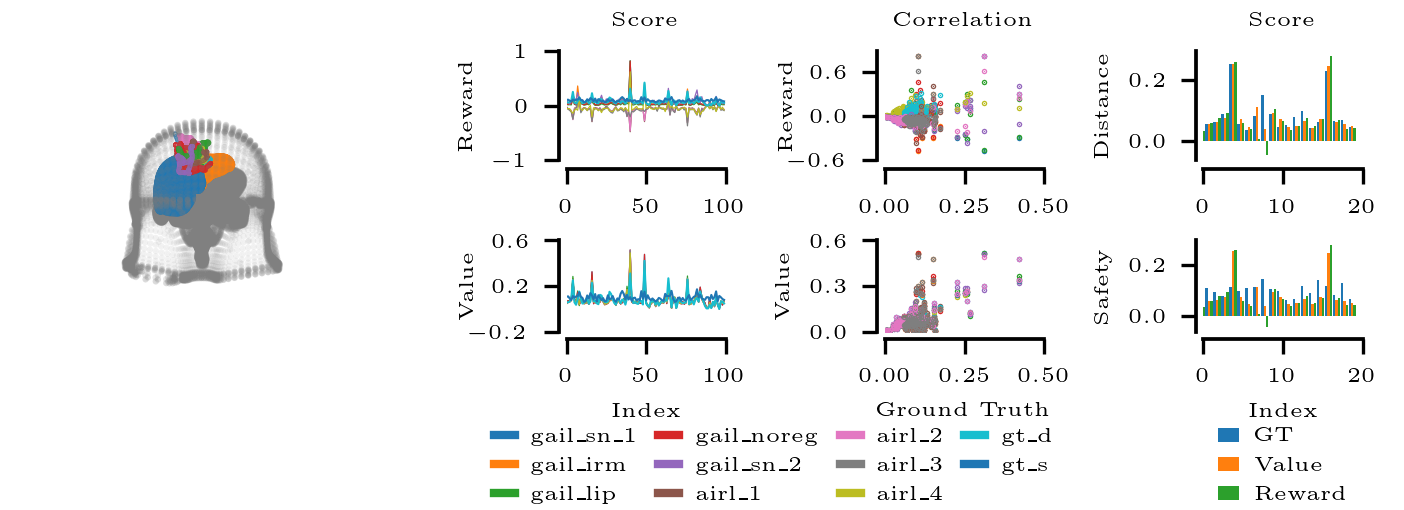

In [342]:

fig, axd = plt.subplot_mosaic(
    [["3dplot", "plot1", "corr1", "hist1"],
     ["3dplot", "plot2", "corr2", "hist2"]],
    layout="tight",
    figsize=(4.68,1.7),
    dpi=300,
    # "image" will contain a square image. We fine-tune the width so that
    # there is no excess horizontal or vertical margin around the image.
    width_ratios=[3, 1, 1,1],
    height_ratios=[1.2,1],

)
fig.tight_layout(w_pad=2.0, h_pad=3.0)


linewidth = .3
# plot reward scores
for k,v in disc_dict.items():
    axd["plot1"].plot(v, label=k, lw=linewidth)
axd["plot1"].plot(dist_sc_normed, label='gt_d', lw=.5)
axd["plot1"].plot(safety_sc_normed, label='gt_s', lw=.5)
axd["plot1"].set_title("Score")

axd["plot1"].set_ylabel('Reward')
axd["plot1"].spines[['top' , 'right']].set_visible(False)
axd["plot1"].spines['left'].set_position(('axes', -0.05))
axd["plot1"].spines['bottom'].set_position(('axes', -0.08))
axd["plot1"].set_yticks([-1, 0, 1])                                          
axd["plot1"].set_xticks([0, 50, 100])                                          
axd["plot1"].set_xlim([0, 100])                                          

# plot value scores
for k,v in val_dict.items():
    axd["plot2"].plot(v, label=k, lw=linewidth)
axd["plot2"].plot(dist_sc_normed, label='gt_d', lw=.5)
axd["plot2"].plot(safety_sc_normed, label='gt_s', lw=.5)

axd["plot2"].set_ylabel('Value',labelpad=-2)
axd["plot2"].set_xlabel('Index')
axd["plot2"].spines[['top' , 'right']].set_visible(False)
axd["plot2"].spines['left'].set_position(('axes', -0.05))
axd["plot2"].spines['bottom'].set_position(('axes', -0.08))
axd["plot2"].set_yticks([-0.2, 0.2, 0.6])                                          
axd["plot2"].set_xticks([0, 50, 100])                                          
axd["plot2"].set_xlim([0, 100])                                          

for k,v in disc_dict.items():
    axd["corr1"].scatter(dist_sc_normed, v, label=k, s=0.1)
    axd["corr1"].scatter(safety_sc_normed, v, label=k, s=0.1)
axd["corr1"].set_ylabel('Reward',labelpad=-2)
axd["corr1"].set_title("Correlation")

axd["corr1"].spines[['top' , 'right']].set_visible(False)
axd["corr1"].spines['left'].set_position(('axes', -0.05))
axd["corr1"].spines['bottom'].set_position(('axes', -0.08))
axd["corr1"].set_yticks([-0.6, 0, 0.6])                                          
axd["corr1"].set_xticks([0, 0.25, 0.5])                                          
axd["corr1"].set_xlim([0, 0.5])           

for k,v in val_dict.items():
    axd["corr2"].scatter(dist_sc_normed, v, label=k, s=0.1)
    axd["corr2"].scatter(safety_sc_normed, v, label=k, s=0.1)
axd["corr2"].set_xlabel('Ground Truth')
axd["corr2"].spines[['top' , 'right']].set_visible(False)
axd["corr2"].spines['left'].set_position(('axes', -0.05))
axd["corr2"].spines['bottom'].set_position(('axes', -0.08))
axd["corr2"].set_ylabel('Value')
axd["corr2"].set_xlabel('Ground Truth')
axd["corr2"].set_yticks([0, 0.3, 0.6])     
axd["corr2"].set_ylim([0,0.6])                                          
axd["corr2"].set_xticks([0, 0.25, 0.5])                                          
axd["corr2"].set_xlim([0, 0.5])           

n_hist_traj = 20
axd["hist1"].bar(np.arange(len(dist_sc_normed[:n_hist_traj]))-0.6, dist_sc_normed[:n_hist_traj], .3, label='GT')
axd["hist1"].bar(np.arange(len(pr_sc_val_ppoairl__[:n_hist_traj]))-0.3, pr_sc_val_ppoairl_[:n_hist_traj], .3, label='Value')
axd["hist1"].bar(np.arange(len(pr_sc_disc_ppoairl__[:n_hist_traj]))+0.0, -pr_sc_disc_ppoairl_[:n_hist_traj], .3, label='Reward')

axd["hist1"].set_ylabel("Distance")
axd["hist1"].set_title("Score")
axd["hist1"].set_xticks([0, n_hist_traj/2, n_hist_traj])                                          
axd["hist1"].set_xlim([0, n_hist_traj])    

axd["hist2"].bar(np.arange(len(safety_sc_normed[:n_hist_traj]))-0.6, safety_sc_normed[:n_hist_traj], .3, label='GT')
axd["hist2"].bar(np.arange(len(pr_sc_val_ppoairl__[:n_hist_traj]))-0.3, pr_sc_val_ppoairl_[:n_hist_traj], .3, label='Value')
axd["hist2"].bar(np.arange(len(pr_sc_disc_ppoairl__[:n_hist_traj]))+0.0, -pr_sc_disc_ppoairl_[:n_hist_traj], .3, label='Reward')

axd["hist2"].set_ylabel("Safety")
axd["hist2"].set_xlabel('Index')
axd["hist2"].set_xticks([0, n_hist_traj/2, n_hist_traj])                                          
axd["hist2"].set_xlim([0, n_hist_traj])    

axd["hist1"].spines[['top' , 'right']].set_visible(False)
axd["hist1"].spines['left'].set_position(('axes', -0.05))
axd["hist1"].spines['bottom'].set_position(('axes', -0.08))
axd["hist2"].spines[['top' , 'right']].set_visible(False)
axd["hist2"].spines['left'].set_position(('axes', -0.05))
axd["hist2"].spines['bottom'].set_position(('axes', -0.08))

### Plot anatomy
axd['3dplot'].remove()
axd['3dplot'] = plt.subplot(1,2,1, projection='3d')
axd['3dplot'].view_init(-45, 90)
axd['3dplot'].dist = 10

#axd['3dplot'].set_xlabel('x')
#axd['3dplot'].set_ylabel('y')
#axd['3dplot'].set_zlabel('z')

# Make panes transparent
axd['3dplot'].xaxis.pane.fill = False # Left pane
axd['3dplot'].yaxis.pane.fill = False # Right pane

# Remove grid lines
axd['3dplot'].grid(False)
axd['3dplot'].axis('off')

# Remove tick labels
axd['3dplot'].set_xticklabels([])
axd['3dplot'].set_yticklabels([])
axd['3dplot'].set_zticklabels([])


# Transparent spines
#axd['3dplot'].w_xaxis.line.set_color((1.0, 1.0, 1.0, 0.0))
#axd['3dplot'].w_yaxis.line.set_color((1.0, 1.0, 1.0, 0.0))
#axd['3dplot'].w_zaxis.line.set_color((1.0, 1.0, 1.0, 0.0))

# Transparent panes
#axd['3dplot'].w_xaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
#axd['3dplot'].w_yaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))

for i, k in enumerate(['LiverRight.obj', 'LiverLeft.obj', 'Falciform.obj']):
    v = obj_dict[k]
    axd['3dplot'].scatter(v[0][:,0],v[0][:,1]+9.8,v[0][:,2], s=1, marker='.', alpha=0.5)

for i, k in enumerate(['ColonRight.obj','ColonTop.obj', 'Stomach.obj', 'GreaterOmentum.obj','ColonLeftRectum.obj', 'Belly.obj', 'DomeOfBladder.obj', 'Uterus.obj']):
    v = obj_dict[k]
    axd['3dplot'].scatter(v[0][:,0],v[0][:,1]+9.8,v[0][:,2], s=1, marker='.' ,alpha=0.1, c='gray')
    
#bb_points = []
max_cnt = 10
cnt = 0
min_x, max_x = 100,-100
min_y, max_y = 100,-100
min_z, max_z = 100,-100

# filter data to correspond to top demos based on which evaluation mesh grid is built
filter_name_list = []
filter_name_list.extend([item[:8] for item in df1[df1['Total score'] >= 145]['Attachments:']])
filter_name_list.extend([item[:8] for item in df2[df2['Total score'] >= 145]['Attachments:']])

filtered_dict = {}
for k,v in data_dict.items():
    filter_flag = (k[:8] in filter_name_list)

    if 'npy' in k and filter_flag:
        filtered_dict[k] = v
        
plot_traj = True
for j, (item_k, item_v) in enumerate(filtered_dict.items()):
    idx = ((item_v[:,-1] >= 12) & (item_v[:,-1] <= 14))
    if plot_traj:
        axd['3dplot'].scatter(item_v[idx,0],item_v[idx,1],item_v[idx,2], s=0.1, marker='.', alpha=0.4)
    if j>10:
        break   
    #min_x, max_x = update_min_max(item_v[idx,0], min_x, max_x)
    #min_y, max_y = update_min_max(item_v[idx,1], min_y, max_y)
    #min_z, max_z = update_min_max(item_v[idx,2], min_z, max_z)

leg = axd["plot2"].legend(loc='upper center', bbox_to_anchor=(1.3, -0.85), fancybox=False, shadow=False, frameon=False, ncol=4, columnspacing=1.0, handlelength=1.0)
for legobj in leg.legendHandles:
    legobj.set_linewidth(2.0)
axd["hist2"].legend(loc='upper center', bbox_to_anchor=(.5, -0.85), fancybox=False, shadow=False, frameon=False, ncol=1, columnspacing=1.0, handlelength=1.0)
plt.subplots_adjust(left=-0.05, bottom=0.35, top=.9)

plt.show()


/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/ipywidgets/widgets/widget.py:477: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  super(Widget, self).__init__(**kwargs)
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/ipywidgets/widgets/widget.py:477: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  super(Widget, self).__init__(**kwargs)
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/ipywidgets/widgets/widget.py:477: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
__init__() missing 1 required positional argument: 'canvas'
This is depreca

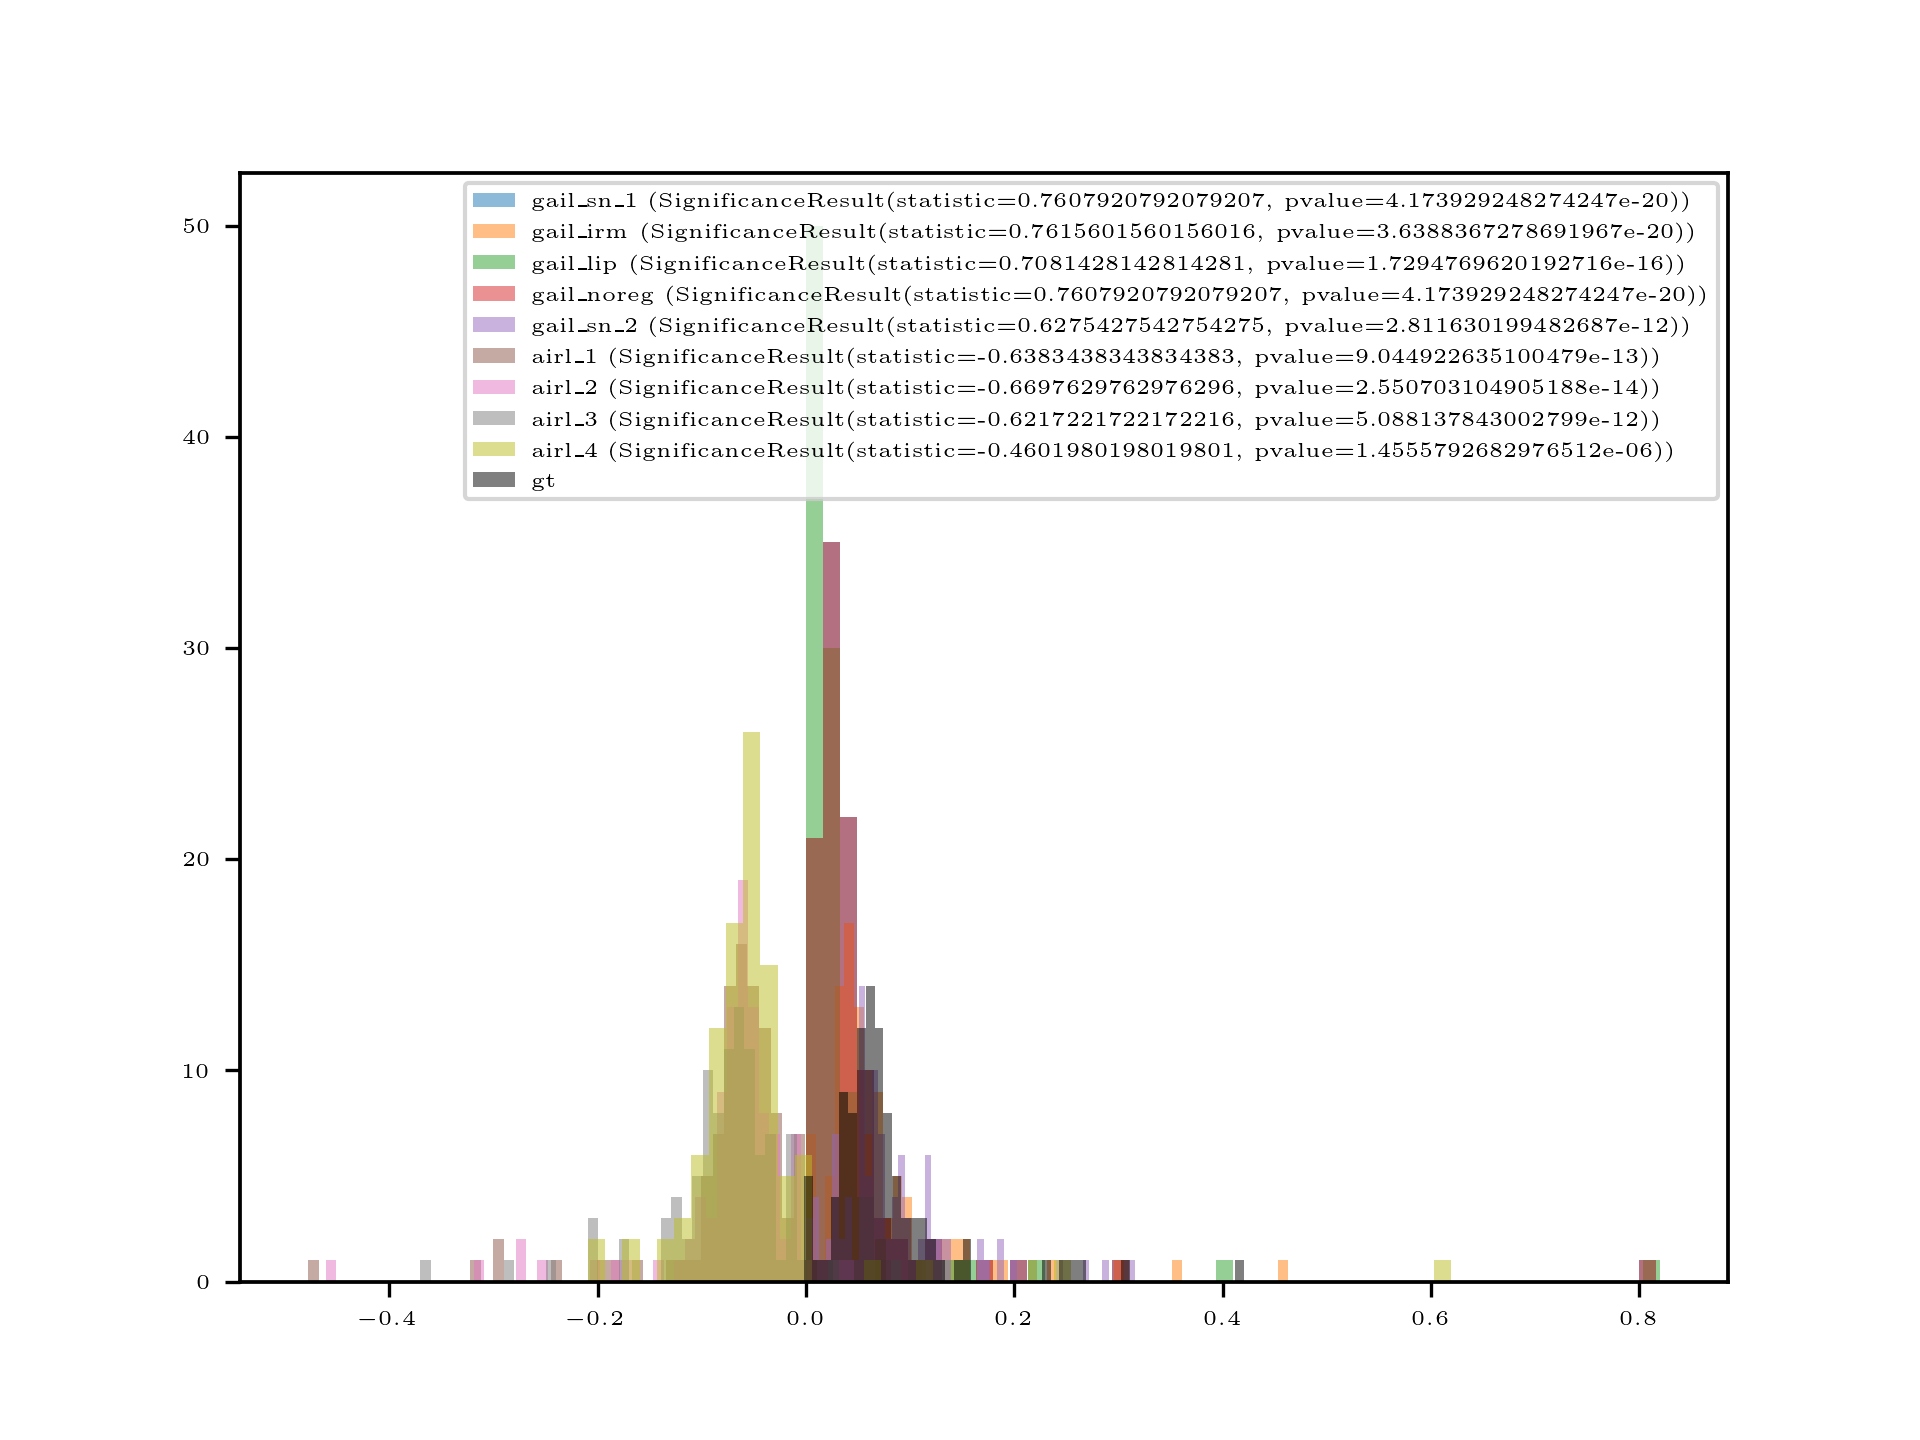

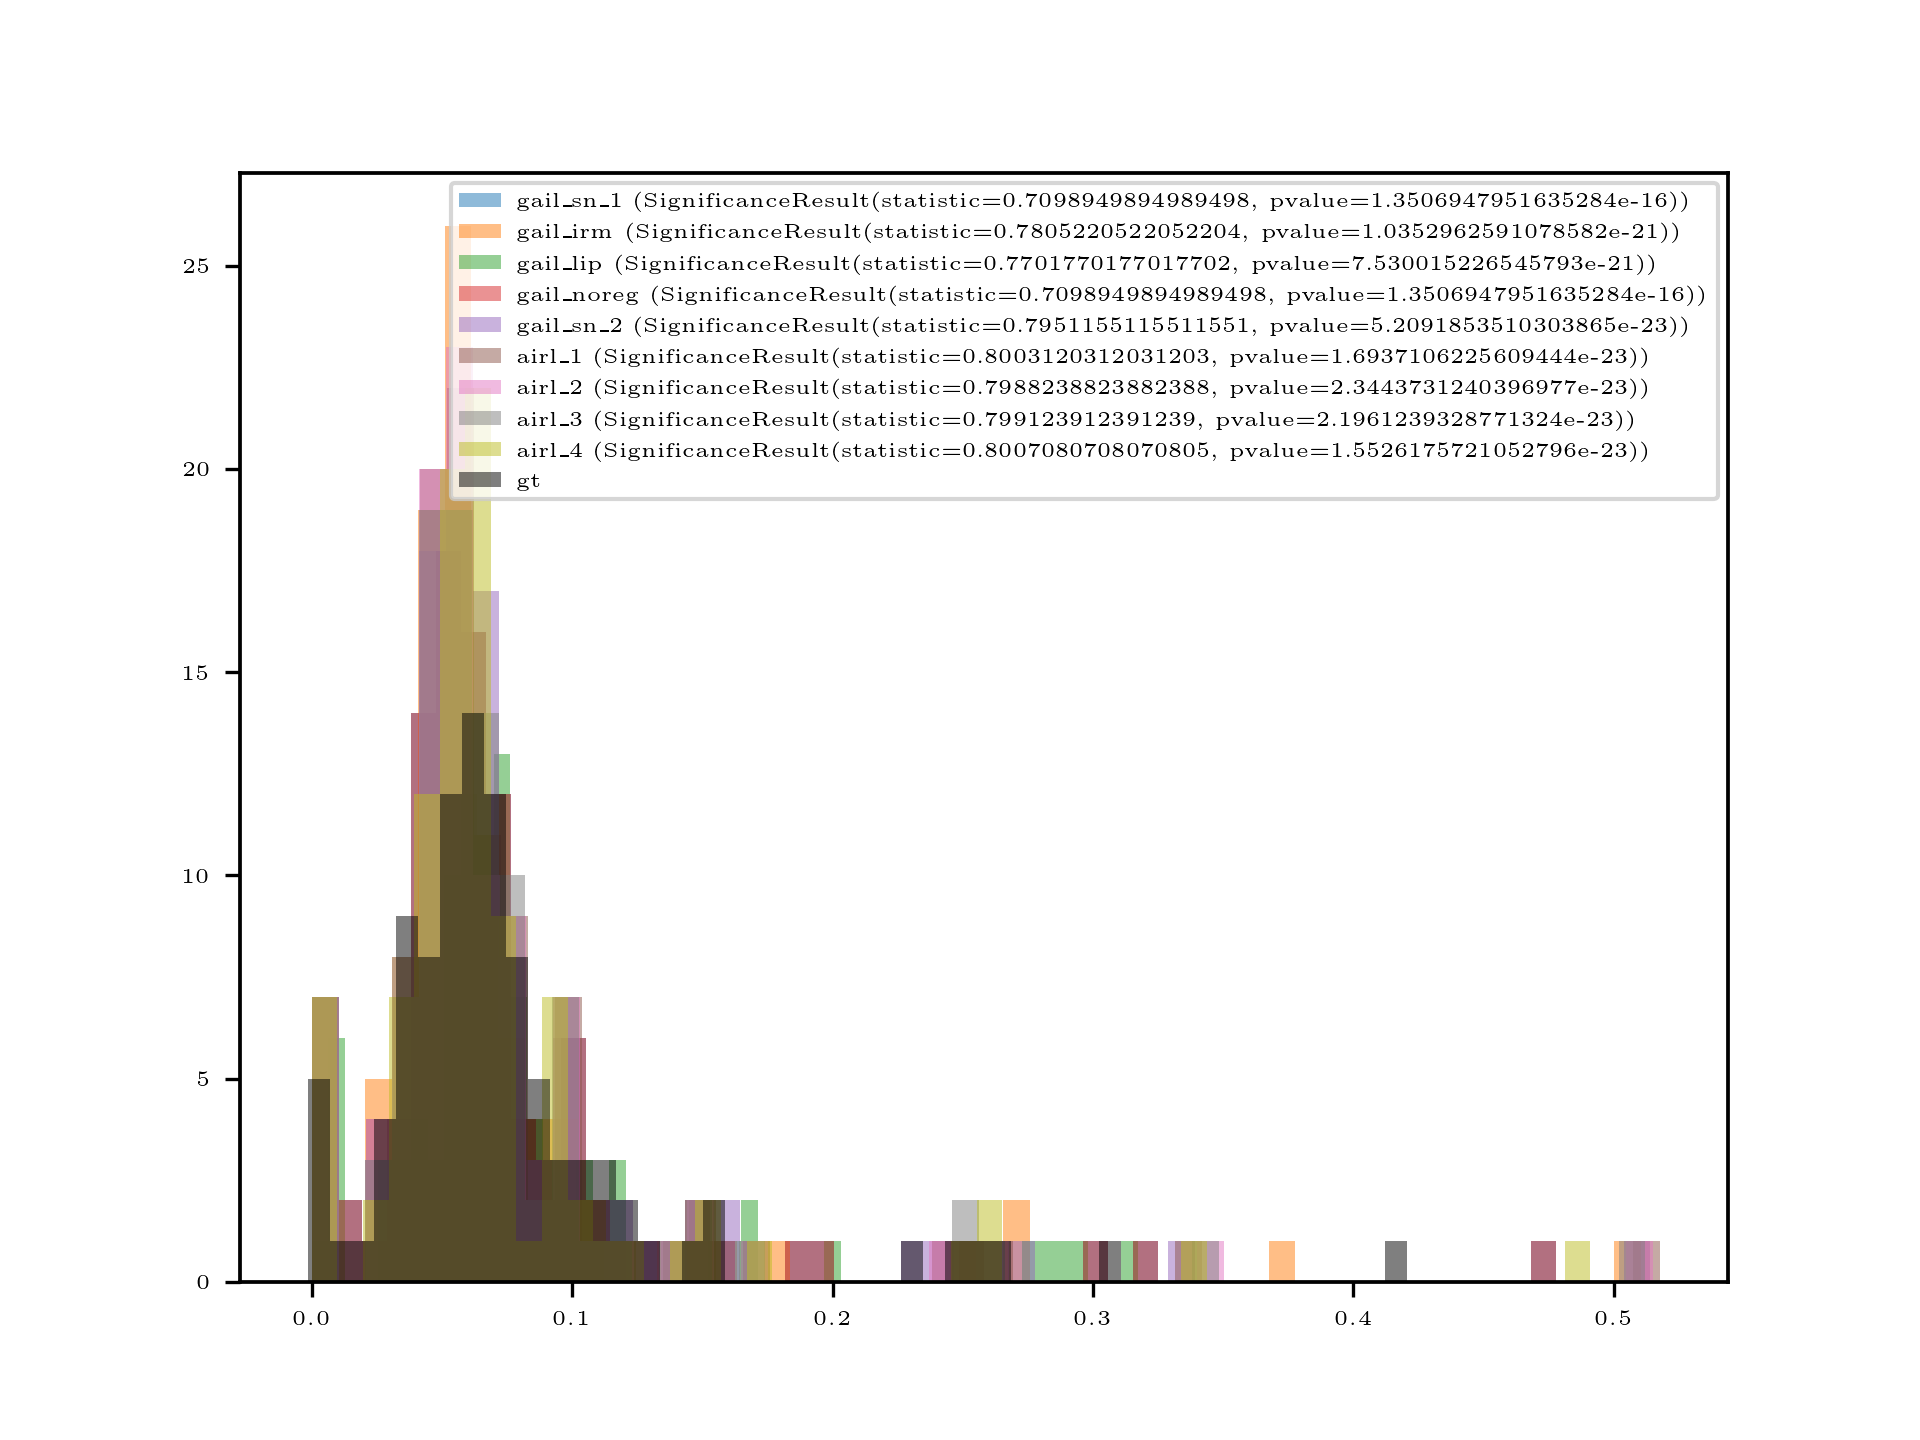

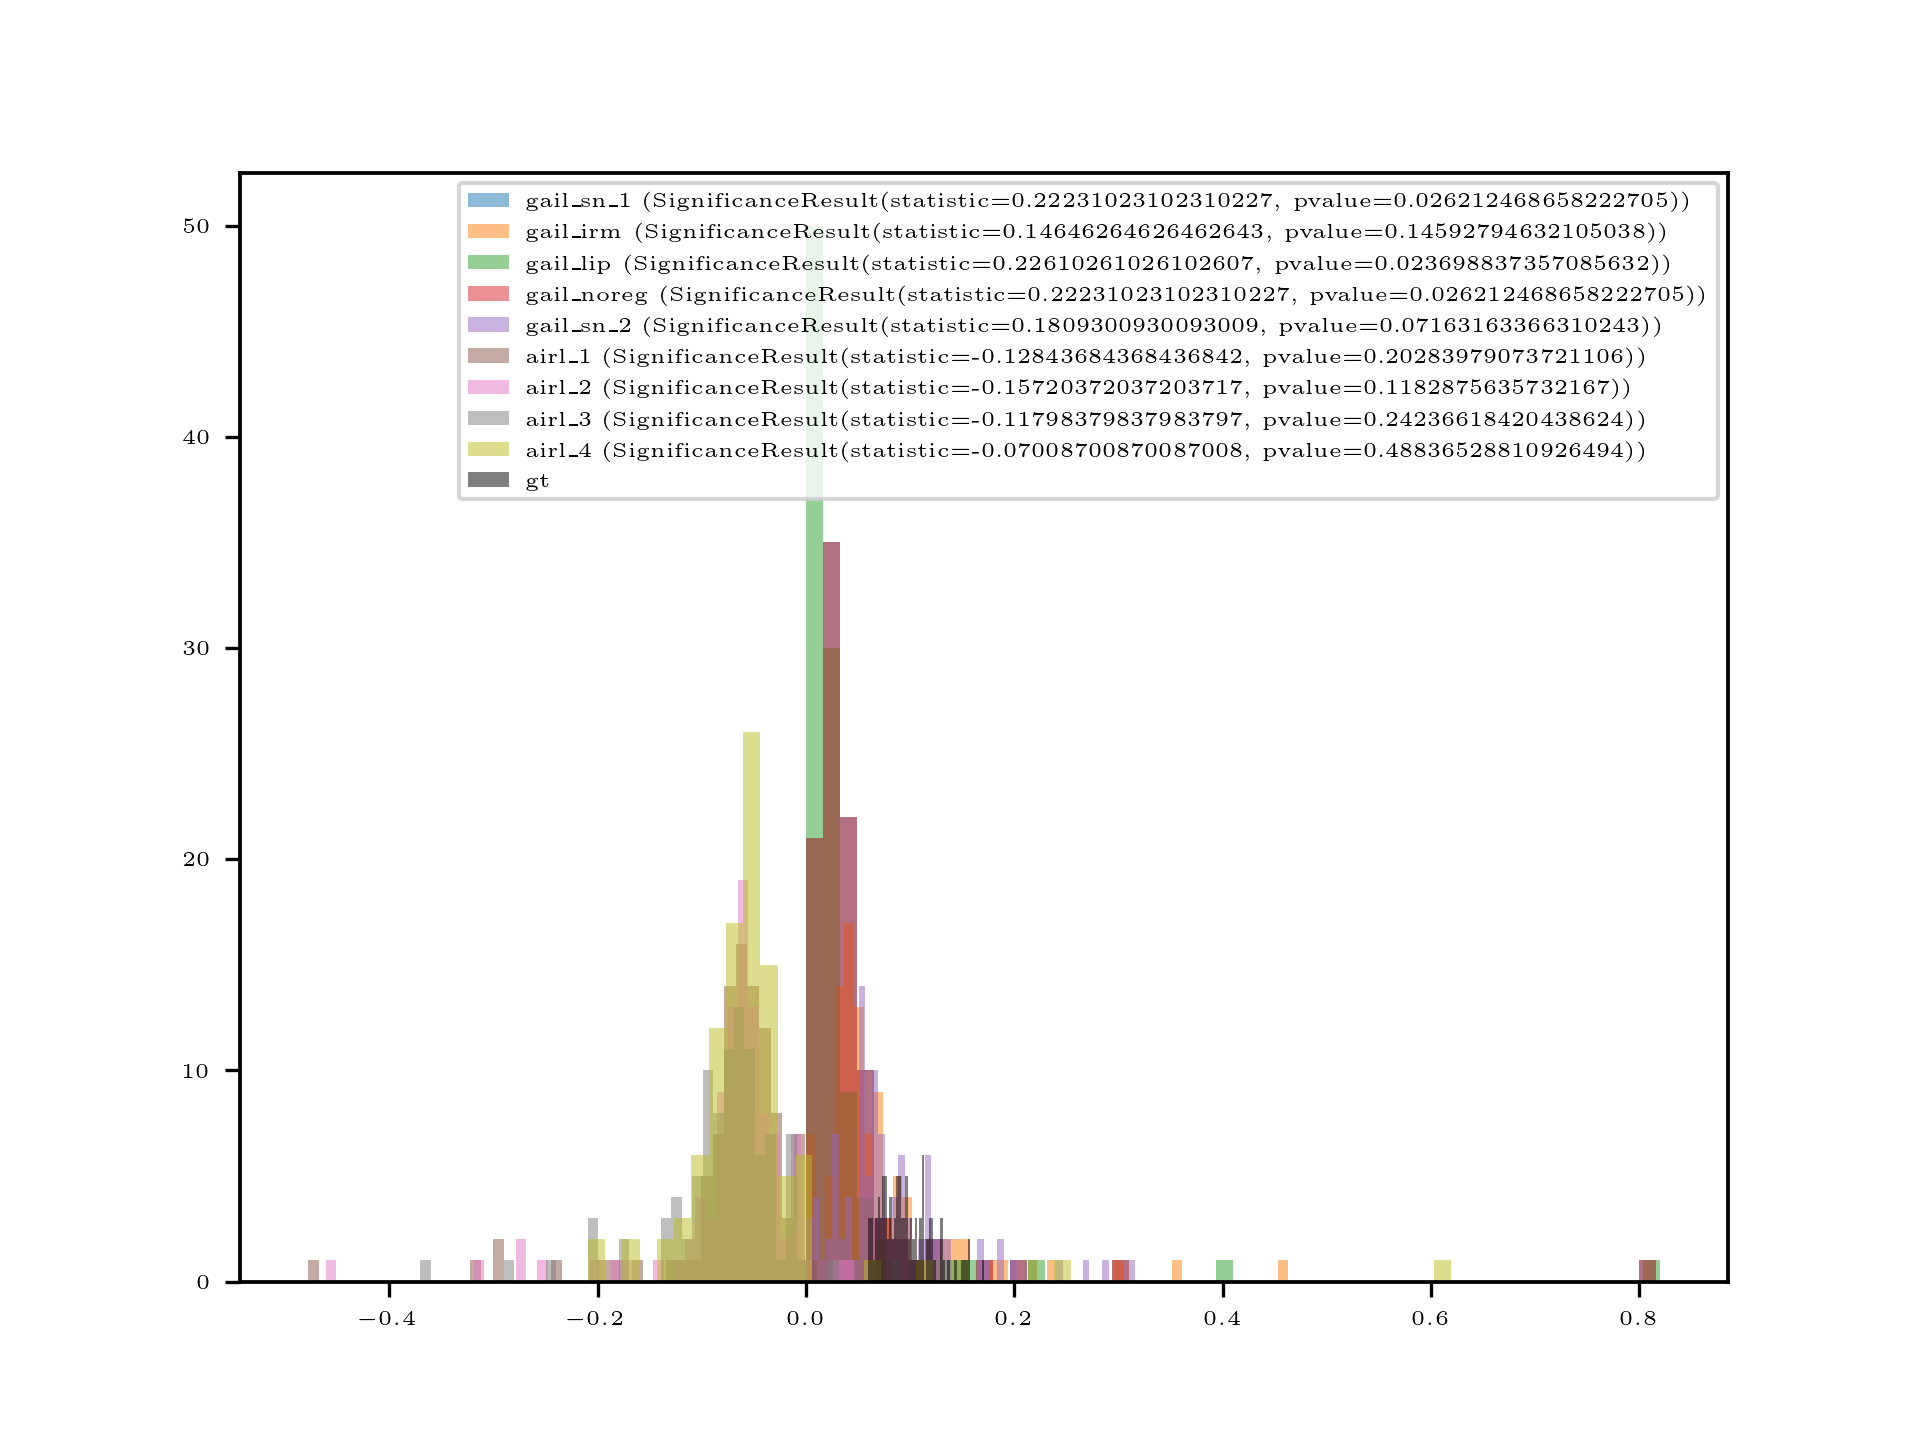

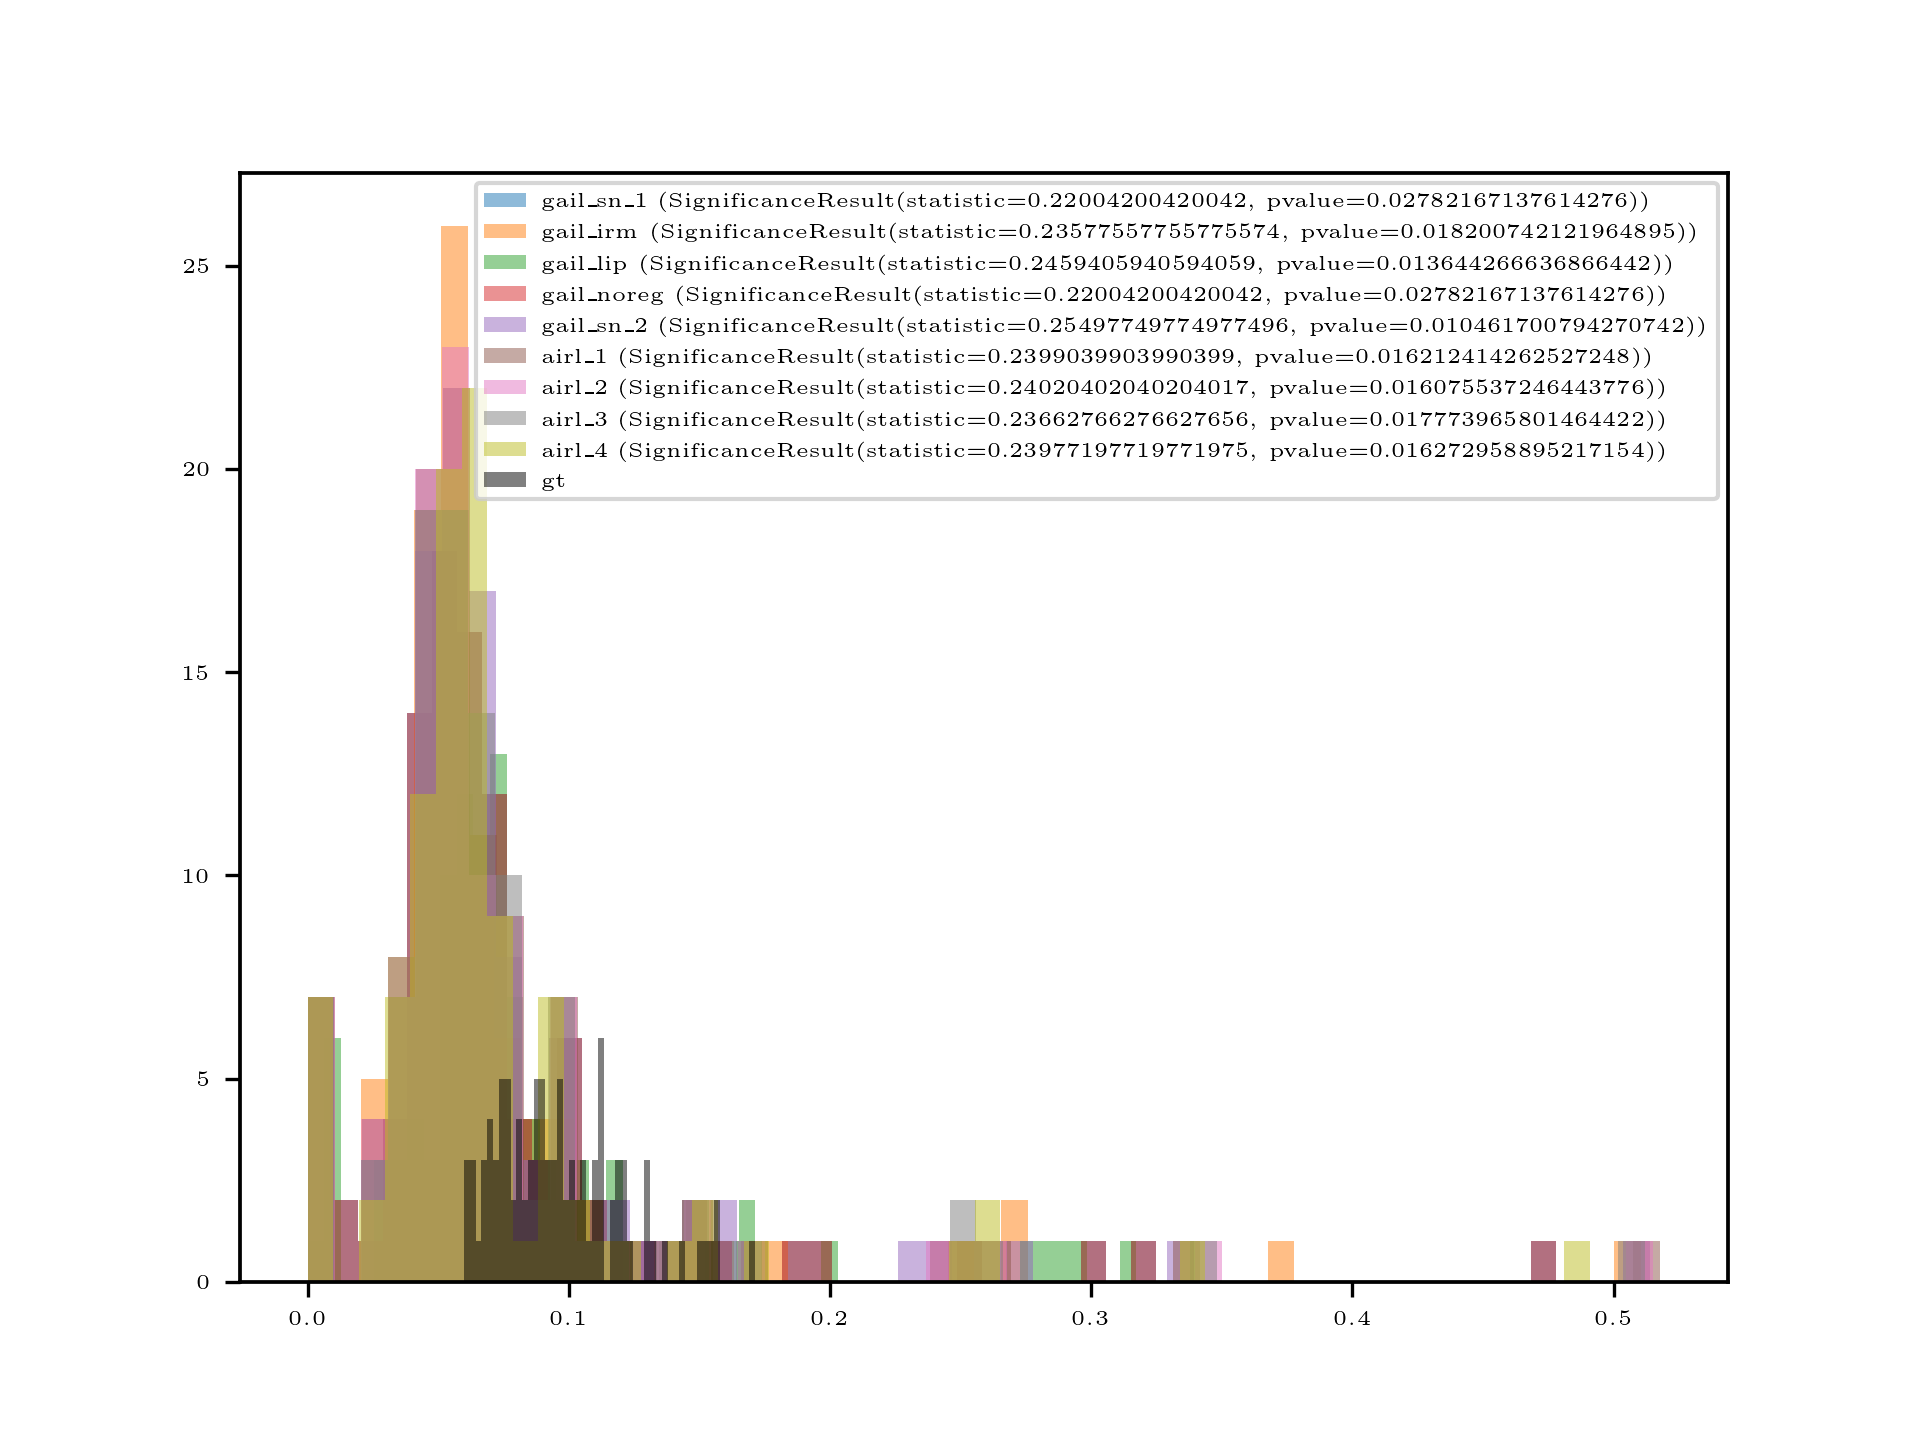

In [271]:
fig= plt.figure(dpi=300)
for k,v in disc_dict.items():
    plt.hist(v, bins=50, alpha=0.5, label=f"{k} ({scipy.stats.spearmanr(dist_sc_normed,v)})")
    
plt.hist(dist_sc_normed, 50, color='k',  label='gt', alpha=0.5)
plt.legend()

fig= plt.figure(dpi=300)

for k,v in val_dict.items():
    plt.hist(v, bins=50, alpha=0.5, label=f"{k} ({scipy.stats.spearmanr(dist_sc_normed,v)})")
plt.hist(dist_sc_normed, 50, color='k',  label='gt', alpha=0.5)
plt.legend()


fig= plt.figure(dpi=300)
for k,v in disc_dict.items():
    plt.hist(v, bins=50, alpha=0.5, label=f"{k} ({scipy.stats.spearmanr(safety_sc_normed,v)[]})")
plt.hist(safety_sc_normed, 50, color='k',  label='gt', alpha=0.5)
plt.legend()

fig= plt.figure(dpi=300)
for k,v in val_dict.items():
    plt.hist(v, bins=50, alpha=0.5, label=f"{k} ({scipy.stats.spearmanr(safety_sc_normed,v)})")
plt.hist(safety_sc_normed, 50, color='k', label='gt', alpha=0.5)
plt.legend()
